<a href="https://colab.research.google.com/github/agboolafaith733-cpu/OIBSIP/blob/main/Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# TASK 2 - Customer Segmentation Analysis
# We group customers based on their buying behaviour using RFM + K-Means

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# For fine charts
sns.set(style="whitegrid")
np.random.seed(42)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
# STEP 2 - Create Customer Data (RFM)
# RFM = Recency (how recently they bought)
#       Frequency (how often they buy)
#       Monetary (how much money they spend)

# Create 300 customers
customers = pd.DataFrame({
    'CustomerID': range(1, 301),
    'Recency': np.random.randint(1, 365, 300),      # days since last purchase
    'Frequency': np.random.randint(1, 50, 300),     # total purchases
    'Monetary': np.random.randint(50, 5000, 300)    # total money spent
})

print(customers.head(10))
print("\nTotal customers:", len(customers))
print(customers.describe())

   CustomerID  Recency  Frequency  Monetary
0           1      103         14      1217
1           2      349         21      2666
2           3      271         48      1112
3           4      107         20      2206
4           5       72          8      3032
5           6      189          7      3344
6           7       21          3      4779
7           8      103         17      1206
8           9      122         33       782
9          10      215         48      4380

Total customers: 300
       CustomerID     Recency   Frequency     Monetary
count  300.000000  300.000000  300.000000   300.000000
mean   150.500000  188.190000   26.293333  2654.376667
std     86.746758  100.892674   13.647765  1409.408238
min      1.000000    2.000000    1.000000    59.000000
25%     75.750000  107.750000   16.000000  1437.000000
50%    150.500000  188.500000   26.500000  2688.000000
75%    225.250000  268.500000   36.000000  3863.500000
max    300.000000  364.000000   49.000000  4998.000000

In [3]:
# STEP 3 - Prepare data and Group Customers with K-Means

# Take only R, F, M columns - no need CustomerID
rfm = customers[['Recency', 'Frequency', 'Monetary']]

# Scaling: make all numbers equal size so computer no go confuse
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# K-Means: Tell computer to make 4 groups
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
customers['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Show how many people dey for each group
print(customers['Cluster'].value_counts())
print("\n")
print(customers.groupby('Cluster').mean(numeric_only=True))

Cluster
0    80
3    79
2    77
1    64
Name: count, dtype: int64


         CustomerID     Recency  Frequency     Monetary
Cluster                                                
0        155.537500  287.700000  17.712500  3277.725000
1        136.921875  240.109375  40.359375  1530.515625
2        155.571429  128.519481  31.792208  4024.935065
3        151.455696  103.518987  18.227848  1597.746835


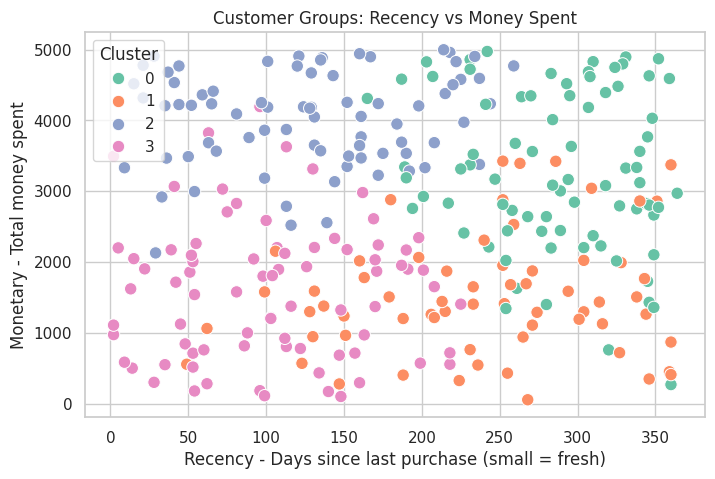

         Recency  Frequency  Monetary
Cluster                              
0          287.7       17.7    3277.7
1          240.1       40.4    1530.5
2          128.5       31.8    4024.9
3          103.5       18.2    1597.7


In [4]:
# STEP 4 - See the groups with charts

plt.figure(figsize=(8,5))
sns.scatterplot(data=customers, x='Recency', y='Monetary', hue='Cluster', palette='Set2', s=80)
plt.title('Customer Groups: Recency vs Money Spent')
plt.xlabel('Recency - Days since last purchase (small = fresh)')
plt.ylabel('Monetary - Total money spent')
plt.show()

# Show full average for each group
print(customers.groupby('Cluster')[['Recency','Frequency','Monetary']].mean().round(1))

In [5]:
# STEP 5 - Conclusion: Name the groups

# Give each Cluster a business name
names = {
    0: 'Lost Customers - Need to win back',
    1: 'Loyal but Quiet - Send offer to return',
    2: 'VIP Best Customers - Take care of them!',
    3: 'New / Occasional - Nurture to become VIP'
}

customers['Segment'] = customers['Cluster'].map(names)
print(customers['Segment'].value_counts())
print("\n--- TASK 2 COMPLETE ---")
print("We used RFM + K-Means to group 300 customers into 4 segments.")
print("Business can now target each group differently.")

Segment
Lost Customers - Need to win back           80
New / Occasional - Nurture to become VIP    79
VIP Best Customers - Take care of them!     77
Loyal but Quiet - Send offer to return      64
Name: count, dtype: int64

--- TASK 2 COMPLETE ---
We used RFM + K-Means to group 300 customers into 4 segments.
Business can now target each group differently.
